
 Without Scaling
Accuracy: 73.59307359307358
Precision: 0.6172839506172839
Recall: 0.625
F1-score: 0.6211180124223602

 With Scaling
Accuracy: 73.59307359307358
Precision: 0.6172839506172839
Recall: 0.625
F1-score: 0.6211180124223602


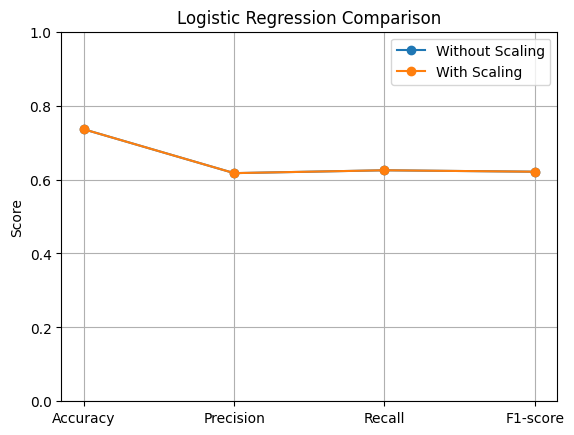

In [6]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler

# Load dataset
df = pd.read_csv(
    "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv",
    header=None,
    names=[
        "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
        "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
    ]
)

# Feature and target extraction
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Without scaling
without_scaling = LogisticRegression(max_iter=1000, random_state=42)
without_scaling.fit(X_train, y_train)
pred_without = without_scaling.predict(X_test)

# With scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

with_scaling = LogisticRegression(max_iter=1000, random_state=42)
with_scaling.fit(X_train_scaled, y_train)
pred_with = with_scaling.predict(X_test_scaled)

# Evaluate performance
for name, pred in [
    ("Without Scaling", pred_without),
    ("With Scaling", pred_with)
]:
    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, pred) * 100)
    print("Precision:", precision_score(y_test, pred))
    print("Recall:", recall_score(y_test, pred))
    print("F1-score:", f1_score(y_test, pred))

# Graph
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

without = [
    accuracy_score(y_test, pred_without),
    precision_score(y_test, pred_without),
    recall_score(y_test, pred_without),
    f1_score(y_test, pred_without)
]

scaled = [
    accuracy_score(y_test, pred_with),
    precision_score(y_test, pred_with),
    recall_score(y_test, pred_with),
    f1_score(y_test, pred_with)
]

plt.plot(metrics, without, marker="o", label="Without Scaling")
plt.plot(metrics, scaled, marker="o", label="With Scaling")
plt.title("Logistic Regression Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend()
plt.grid()
plt.show()
